# 02 · Signal filtering and PQRST detection

Studies the filtering chain on leads III and V4 (0.5 Hz high-pass → 50 Hz notch → 100 Hz low-pass), frequency spectra, Pan-Tompkins R-peak detection and P/Q/S/T localisation. Note: this exploration uses Butterworth order 5; the feature notebooks and the web app use order 4.

> Originally run on Google Colab; saved outputs are kept. Set the paths below to rerun locally.

In [ ]:
# Paths — put the PhysioNet zip files in DATA_DIR (see ../data/README.md)
import os
import pandas as pd

DATA_DIR = "../data/raw"        # ptb-diagnostic-ecg-database-1.0.0.zip, european-st-t-database-1.0.0.zip
WORK_DIR = "../data/work"       # extracted records and intermediate CSVs
LABELS_CSV = "../data/labels.csv"
os.makedirs(WORK_DIR, exist_ok=True)


def load_patient_labels():
    """Diagnosis of each ischemic patient (replaces the original data2.csv)."""
    df = pd.read_csv(LABELS_CSV)
    df = df[df.label > 0]
    return pd.DataFrame({"ID patient ": df.record, "label": df.label_name})


In [2]:
import os
import zipfile
import shutil

# Input zip paths
data_dir = DATA_DIR
ptb_zip_path = os.path.join(data_dir, 'ptb-diagnostic-ecg-database-1.0.0.zip')
european_zip_path = os.path.join(data_dir, 'european-st-t-database-1.0.0.zip')

# Output structure
output_base = f"{WORK_DIR}/ECG_Data"
ischemic_dir = os.path.join(output_base, 'Ischemic')
normal_dir = os.path.join(output_base, 'Normal')
os.makedirs(ischemic_dir, exist_ok=True)
os.makedirs(normal_dir, exist_ok=True)

# Temporary extract folders
ptb_temp = f"{WORK_DIR}/ptb-temp"
european_temp = f"{WORK_DIR}/european-temp"

# --- Unzip PTB ---
with zipfile.ZipFile(ptb_zip_path, 'r') as zip_ref:
    zip_ref.extractall(ptb_temp)

ptb_root = os.path.join(ptb_temp, 'ptb-diagnostic-ecg-database-1.0.0')

# Flatten PTB: Copy and rename files
for patient_folder in os.listdir(ptb_root):
    full_path = os.path.join(ptb_root, patient_folder)
    if os.path.isdir(full_path):
        for fname in os.listdir(full_path):
            src = os.path.join(full_path, fname)
            base_name = f"{fname}"  # Avoid filename collisions
            dst = os.path.join(normal_dir, base_name)
            shutil.copyfile(src, dst)

# --- Unzip European ST-T ---
with zipfile.ZipFile(european_zip_path, 'r') as zip_ref:
    zip_ref.extractall(european_temp)

european_root = os.path.join(european_temp, 'european-st-t-database-1.0.0')

# Copy all files from European ST-T
for fname in os.listdir(european_root):
    src = os.path.join(european_root, fname)
    dst = os.path.join(ischemic_dir, fname)
    shutil.copyfile(src, dst)


In [3]:
!pip install wfdb

In [5]:
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=5):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=5):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # 1. High-pass filter (e.g., 0.5 Hz)
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter (e.g., 45 Hz)

    # 3. Notch filter (e.g., 50 Hz or 60 Hz depending on country)
    signal = notch_filter(signal, 50.0, fs)  # Use 60.0 if you're in North America
    signal = lowpass_filter(signal,100.0, fs)

    return signal


In [6]:
ListFilesIschemiques=os.listdir(f"{WORK_DIR}/ECG_Data/Ischemic")
ListFilesIschemiques=[x for x in ListFilesIschemiques if x[-4:]=='.dat' ]
print(len(ListFilesIschemiques))
ListFilesIschemiques


31


['e0123.dat',
 'e0122.dat',
 'e0159.dat',
 'e0103.dat',
 'e0126.dat',
 'e0114.dat',
 'e0107.dat',
 'e0148.dat',
 'e0166.dat',
 'e0154.dat',
 'e0147.dat',
 'e0119.dat',
 'e0121.dat',
 'e0105.dat',
 'e0161.dat',
 'e0104.dat',
 'e0111.dat',
 'e0127.dat',
 'e0118.dat',
 'e0163.dat',
 'e0136.dat',
 'e0124.dat',
 'e0139.dat',
 'e0155.dat',
 'e0108.dat',
 'e0125.dat',
 'e0112.dat',
 'e0170.dat',
 'e0116.dat',
 'e0113.dat',
 'e0162.dat']

In [7]:
ListFilesNormales=os.listdir(f"{WORK_DIR}/ECG_Data/Normal")
ListFilesNormales=[x for x in ListFilesNormales if x[-4:]=='.dat' ]
print(len(ListFilesNormales))
ListFilesNormales


80


['s0478_re.dat',
 's0476_re.dat',
 's0302lre.dat',
 's0552_re.dat',
 's0323lre.dat',
 's0458_re.dat',
 's0481_re.dat',
 's0499_re.dat',
 's0526_re.dat',
 's0308lre.dat',
 's0470_re.dat',
 's0436_re.dat',
 's0527_re.dat',
 's0532_re.dat',
 's0545_re.dat',
 's0460_re.dat',
 's0452_re.dat',
 's0469_re.dat',
 's0482_re.dat',
 's0363lre.dat',
 's0490_re.dat',
 's0472_re.dat',
 's0402lre.dat',
 's0480_re.dat',
 's0462_re.dat',
 's0329lre.dat',
 's0473_re.dat',
 's0474_re.dat',
 's0531_re.dat',
 's0287lre.dat',
 's0299lre.dat',
 's0496_re.dat',
 's0301lre.dat',
 's0274lre.dat',
 's0273lre.dat',
 's0467_re.dat',
 's0543_re.dat',
 's0561_re.dat',
 's0291lre.dat',
 's0468_re.dat',
 's0300lre.dat',
 's0502_re.dat',
 's0459_re.dat',
 's0504_re.dat',
 's0415lre.dat',
 's0306lre.dat',
 's0500_re.dat',
 's0466_re.dat',
 's0305lre.dat',
 's0303lre.dat',
 's0551_re.dat',
 's0471_re.dat',
 's0483_re.dat',
 's0464_re.dat',
 's0486_re.dat',
 's0479_re.dat',
 's0374lre.dat',
 's0534_re.dat',
 's0491_re.dat

In [8]:
###################### Normal #########################

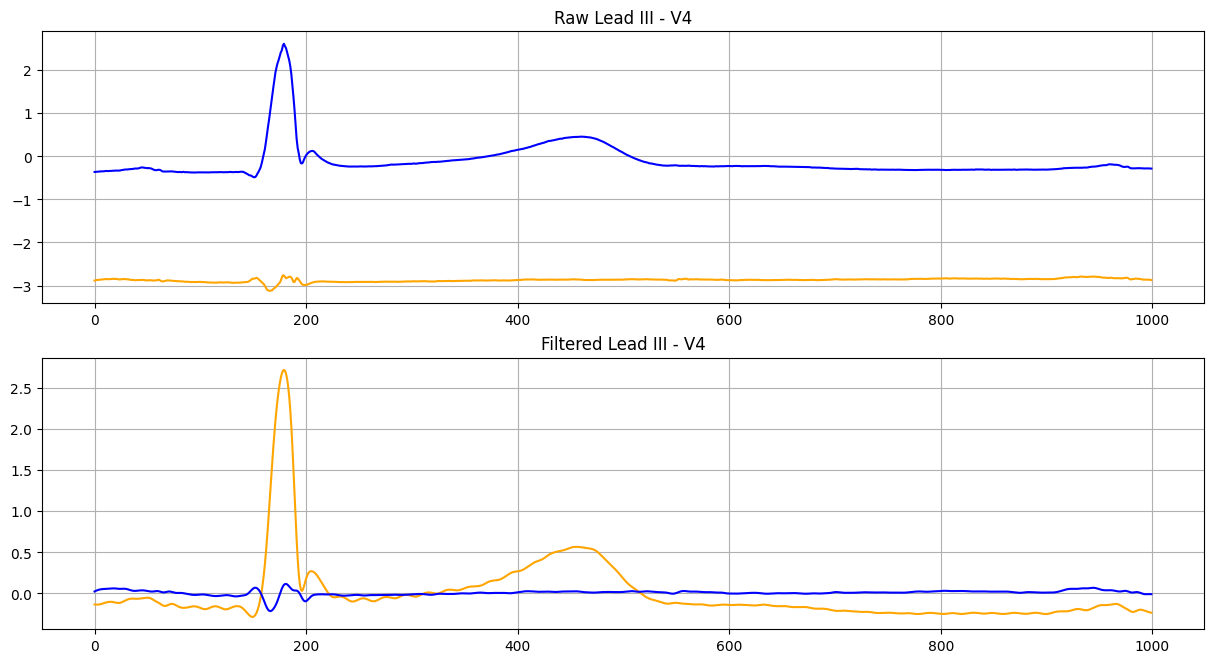

In [12]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
i = 6
path = f"{WORK_DIR}/ECG_Data/Normal/"

if i >= len(ListFilesNormales):
    z = len(ListFilesNormales) - 1
elif i < 0:
    z = 0
else:
    z = i

record = wfdb.rdrecord(f'{path}/{ListFilesNormales[z][:-4]}')
fs = record.fs
channel_names = record.sig_name

# Get each lead separately
idx_iii = channel_names.index('iii')
idx_v4 = channel_names.index('v4')

lead_iii = record.p_signal[:, idx_iii]
lead_v4 = record.p_signal[:, idx_v4]

# Filter each lead
filtered_iii = preprocess_ecg(lead_iii, fs)
filtered_v4 = preprocess_ecg(lead_v4, fs)

# Normalize
normalized_iii =filtered_iii# (filtered_iii - np.mean(filtered_iii)) / np.std(filtered_iii)
normalized_v4 = filtered_v4#(filtered_v4 - np.mean(filtered_v4)) / np.std(filtered_v4)

# === Plot results ===
plt.figure(figsize=(15, 12))

plt.subplot(3, 1,1)
plt.plot(lead_iii[:1000], color='orange')
plt.plot(lead_v4[:1000], color='blue')

plt.title("Raw Lead III - V4")
plt.grid(True)



plt.subplot(3, 1,2)

plt.plot(filtered_v4[:1000], color='orange')

plt.plot(filtered_iii[:1000], color='blue')
plt.title("Filtered Lead III - V4")
plt.grid(True)




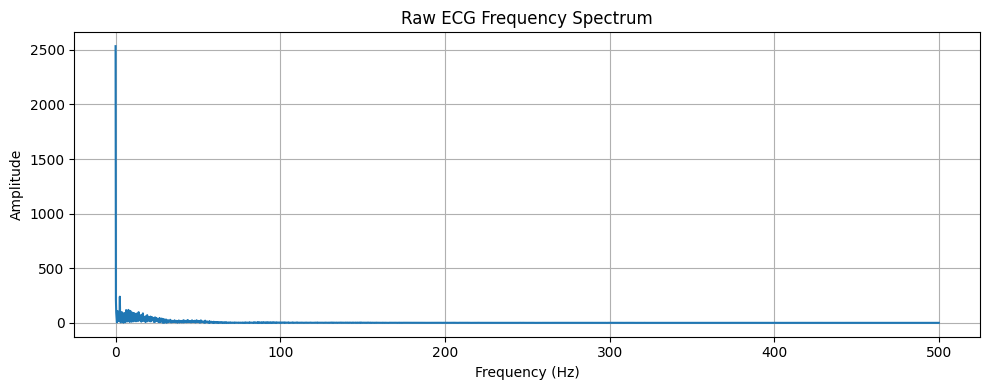

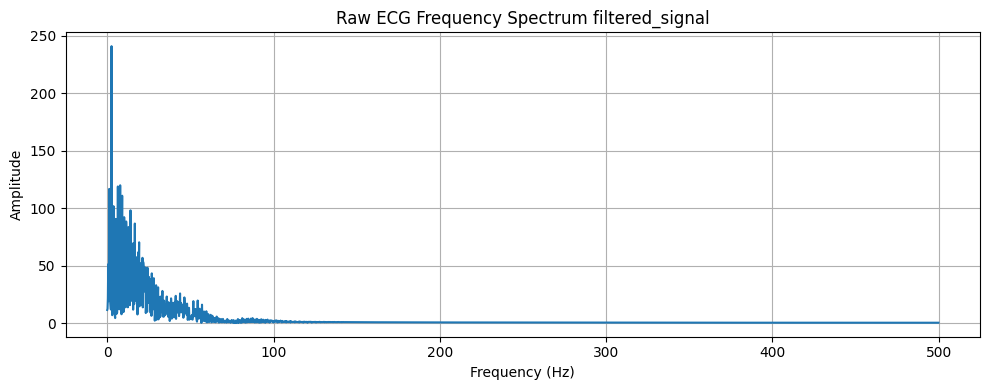

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(lead_iii[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_iii[:5000], fs, title="Raw ECG Frequency Spectrum filtered_signal")


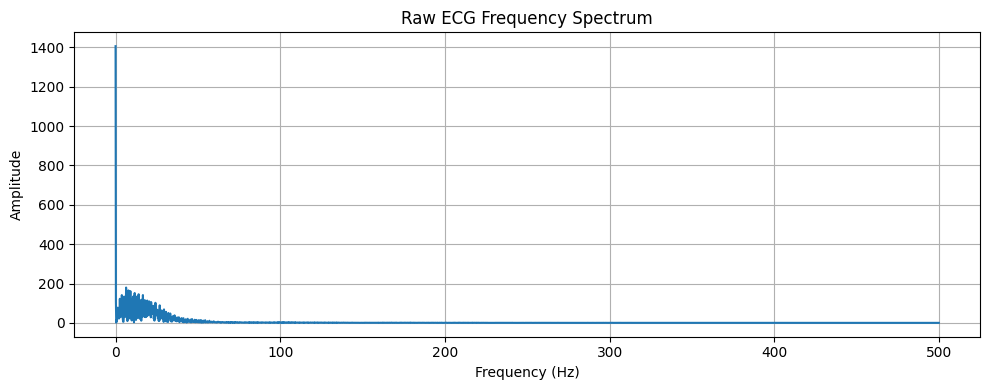

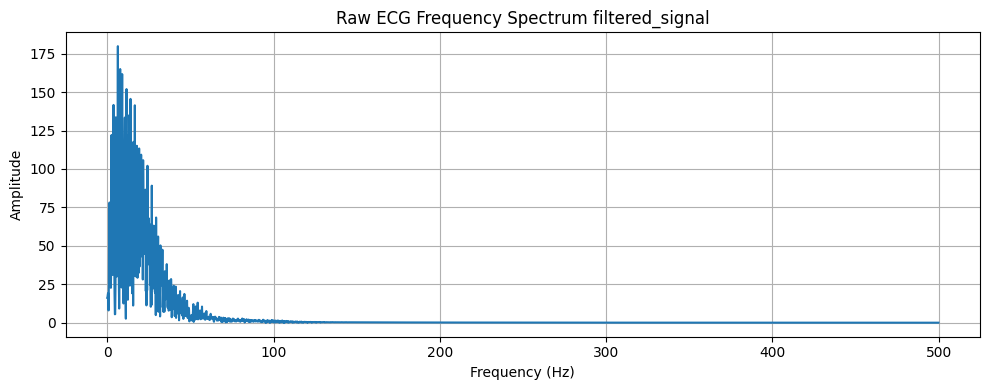

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(lead_v4[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_v4[:5000], fs, title="Raw ECG Frequency Spectrum filtered_signal")


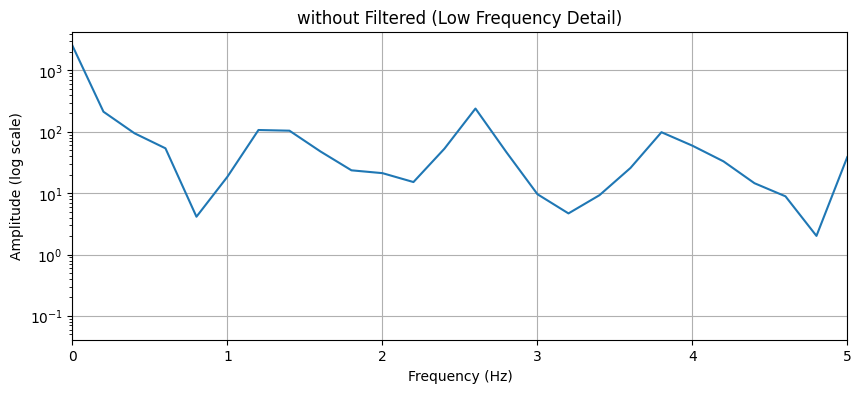

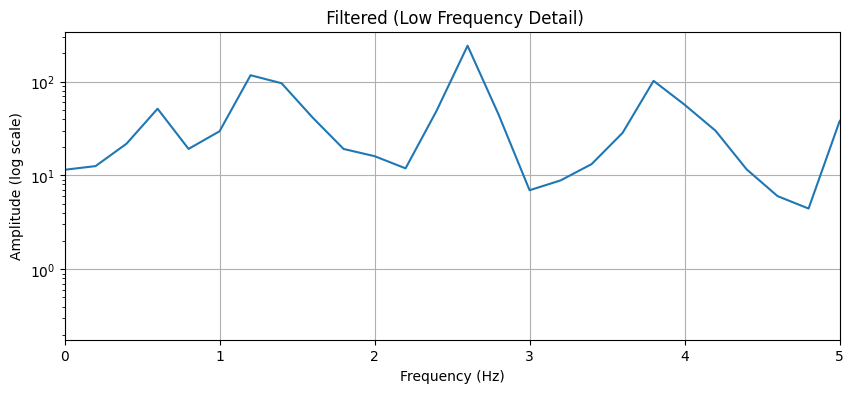

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(lead_iii[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_iii[:5000], fs, " Filtered")


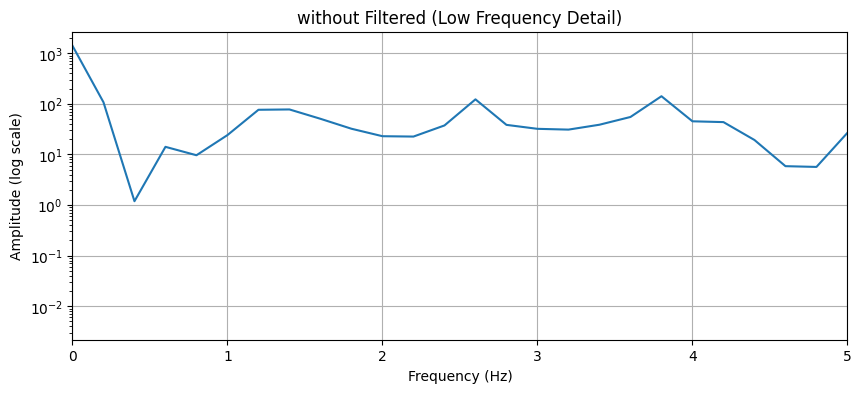

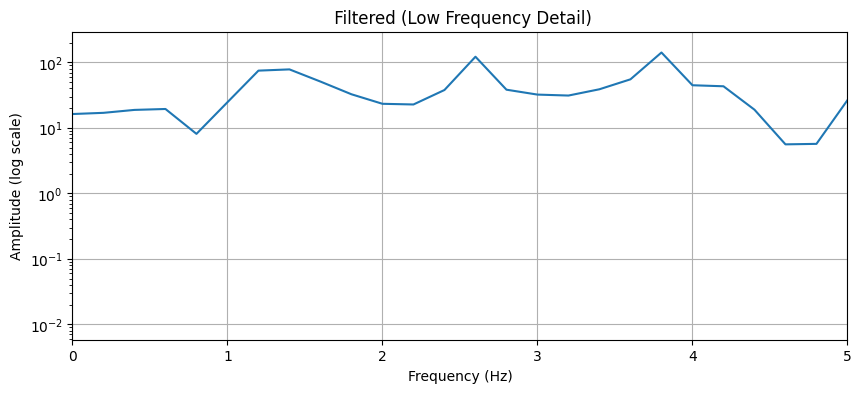

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(lead_v4[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_v4[:5000], fs, " Filtered")


In [ ]:
from scipy.signal import find_peaks


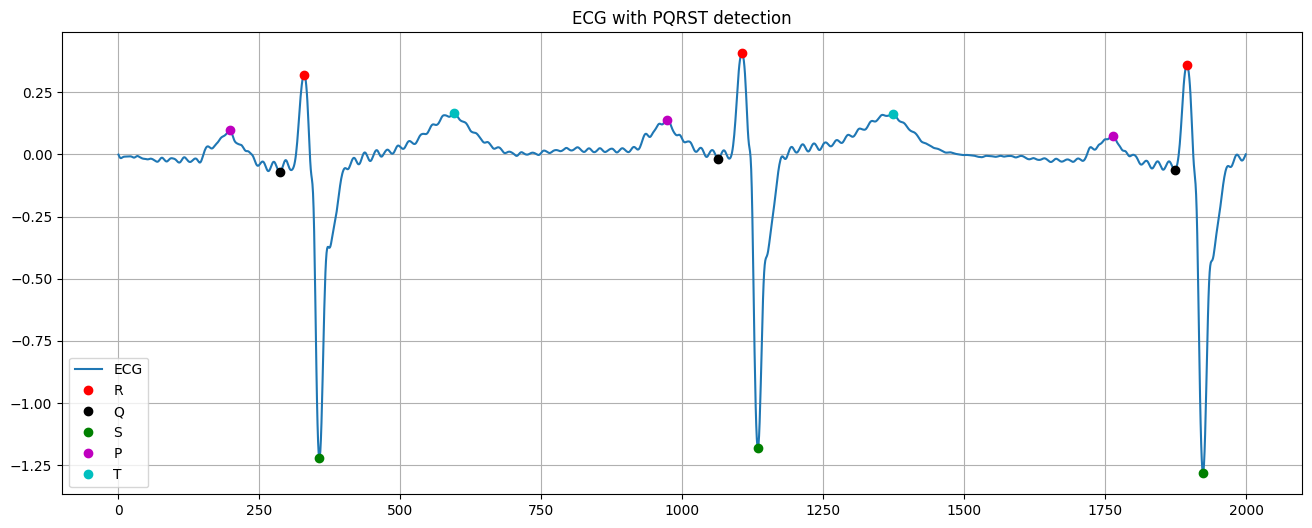

In [ ]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np

def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa


r_peaks, mwa_signal = pan_tompkins(filtered_iii, fs)


# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(filtered_iii, r_peaks, fs)

# === Plot with all points ===
plt.figure(figsize=(16, 6))
plt.plot(filtered_iii[:2000], label="ECG")
plt.plot(r_peaks[r_peaks < 2000], filtered_iii[r_peaks[r_peaks < 2000]], 'ro', label="R")
plt.plot(q_waves[q_waves < 2000], filtered_iii[q_waves[q_waves < 2000]], 'ko', label="Q")
plt.plot(s_waves[s_waves < 2000], filtered_iii[s_waves[s_waves < 2000]], 'go', label="S")
plt.plot(p_waves[p_waves < 2000], filtered_iii[p_waves[p_waves < 2000]], 'mo', label="P")
plt.plot(t_waves[t_waves < 2000], filtered_iii[t_waves[t_waves < 2000]], 'co', label="T")
plt.title("ECG with PQRST detection")
plt.legend()
plt.grid()
plt.show()

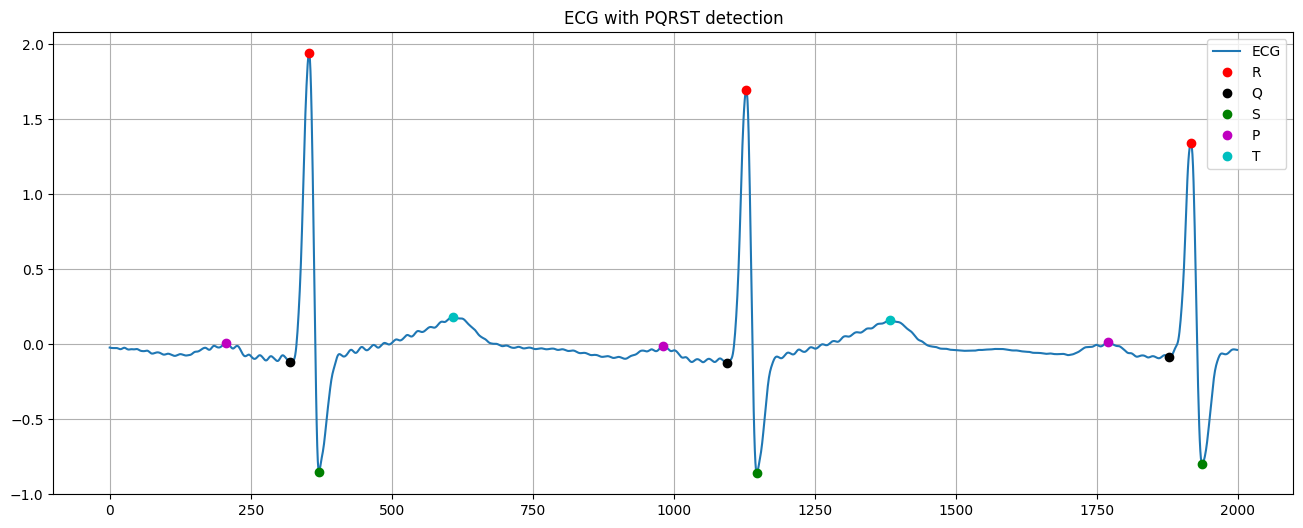

In [ ]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np

def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa


r_peaks, mwa_signal = pan_tompkins(filtered_v4, fs)


# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(filtered_v4, r_peaks, fs)

# === Plot with all points ===
plt.figure(figsize=(16, 6))
plt.plot(filtered_v4[:2000], label="ECG")
plt.plot(r_peaks[r_peaks < 2000], filtered_v4[r_peaks[r_peaks < 2000]], 'ro', label="R")
plt.plot(q_waves[q_waves < 2000], filtered_v4[q_waves[q_waves < 2000]], 'ko', label="Q")
plt.plot(s_waves[s_waves < 2000], filtered_v4[s_waves[s_waves < 2000]], 'go', label="S")
plt.plot(p_waves[p_waves < 2000], filtered_v4[p_waves[p_waves < 2000]], 'mo', label="P")
plt.plot(t_waves[t_waves < 2000], filtered_v4[t_waves[t_waves < 2000]], 'co', label="T")
plt.title("ECG with PQRST detection filtered_v4 normal")
plt.legend()
plt.grid()
plt.show()

In [ ]:
####################### Ischemique #############

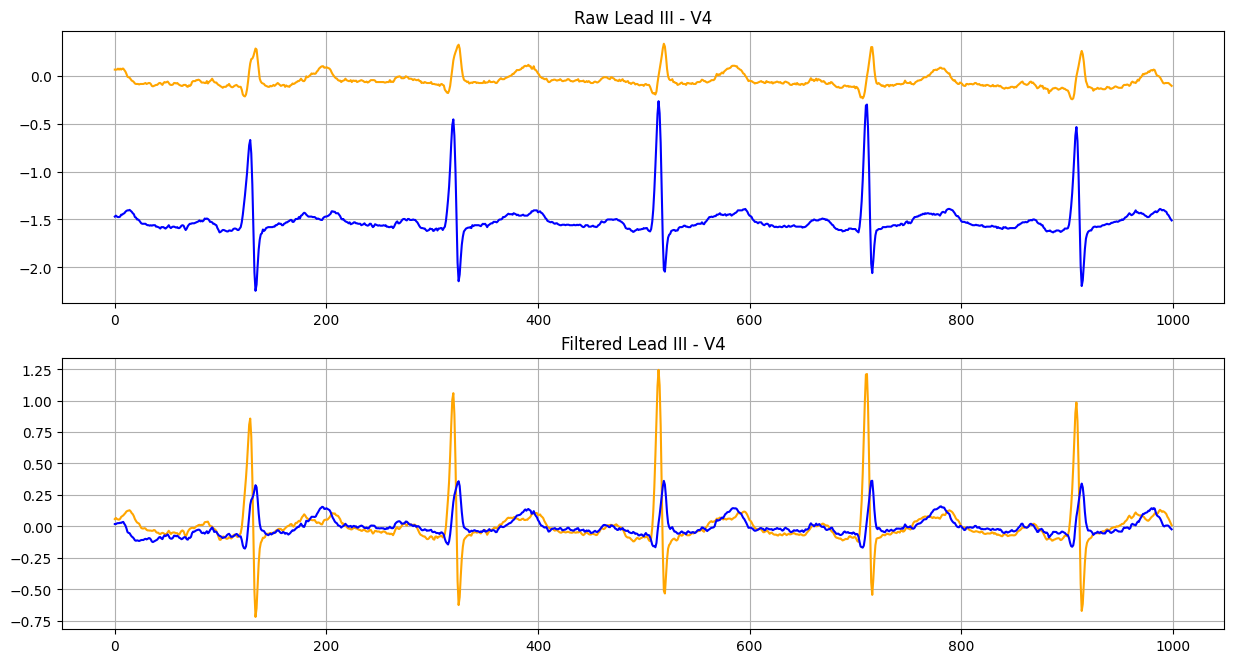

In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch

i=0
path=f"{WORK_DIR}/ECG_Data/Ischemic"
if i> len(ListFilesIschemiques) :
  z=len(ListFilesIschemiques)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesIschemiques[z][:-4]}')
fs = record.fs
channel_names = record.sig_name

# Get each lead separately
idx_iii = channel_names.index('MLIII')
idx_v4 = channel_names.index('V4')

lead_iii = record.p_signal[:, idx_iii]
lead_v4 = record.p_signal[:, idx_v4]

# Filter each lead
filtered_iii = preprocess_ecg(lead_iii, fs)
filtered_v4 = preprocess_ecg(lead_v4, fs)



# === Plot results ===
plt.figure(figsize=(15, 12))

plt.subplot(3, 1,1)
plt.plot(lead_iii[:1000], color='orange')
plt.plot(lead_v4[:1000], color='blue')

plt.title("Raw Lead III - V4")
plt.grid(True)



plt.subplot(3, 1,2)

plt.plot(filtered_v4[:1000], color='orange')

plt.plot(filtered_iii[:1000], color='blue')
plt.title("Filtered Lead III - V4")
plt.grid(True)




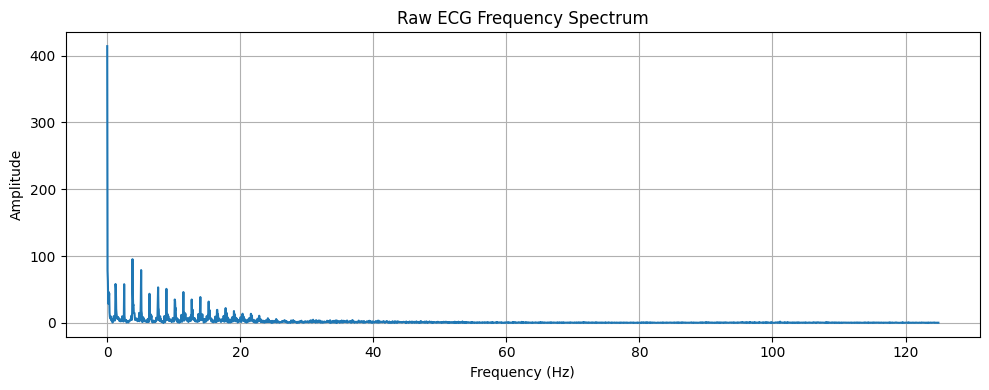

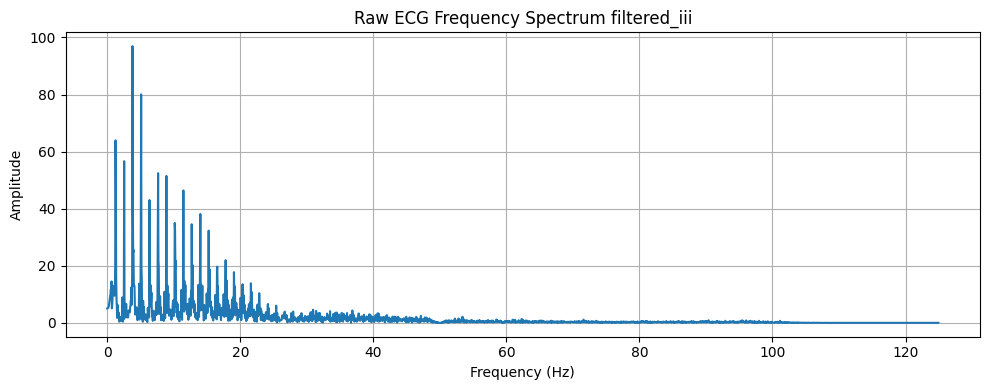

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(lead_iii[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_iii[:5000], fs, title="Raw ECG Frequency Spectrum filtered_iii")


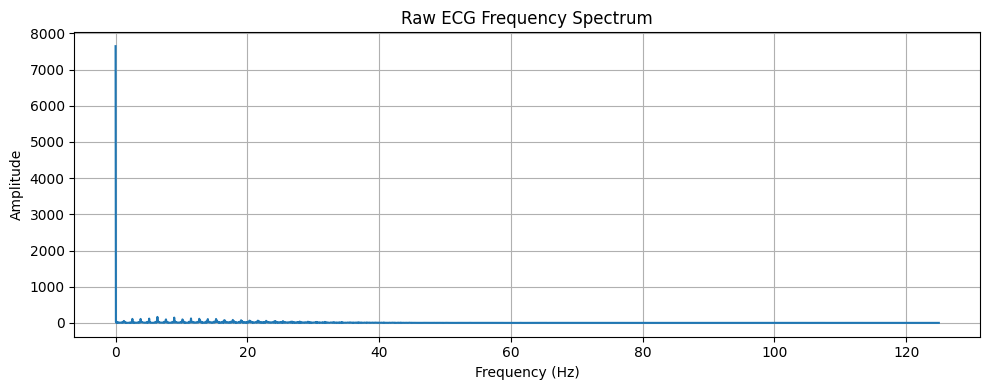

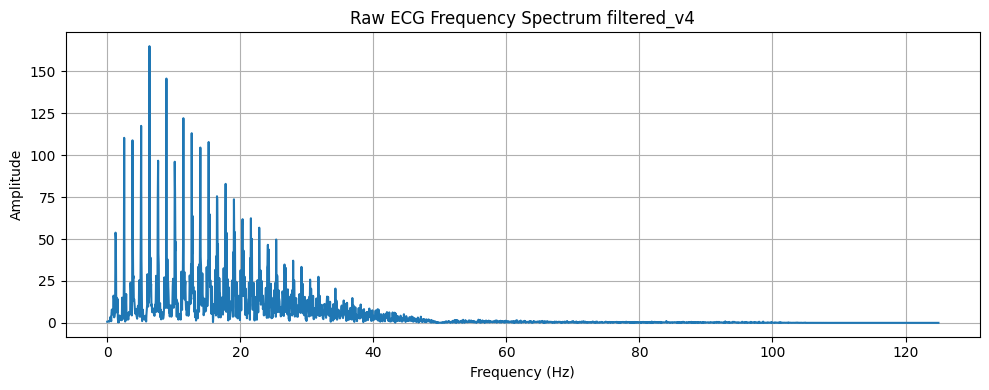

In [ ]:
from scipy.fft import fft, fftfreq

def plot_frequency_spectrum(signal, fs, title="Frequency Spectrum"):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1 / fs)

    plt.figure(figsize=(10, 4))
    plt.plot(xf[:N // 2], yf[:N // 2])
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude")
    plt.grid()
    plt.tight_layout()
    plt.show()

plot_frequency_spectrum(lead_v4[:5000], fs, title="Raw ECG Frequency Spectrum")
plot_frequency_spectrum(filtered_v4[:5000], fs, title="Raw ECG Frequency Spectrum filtered_v4")


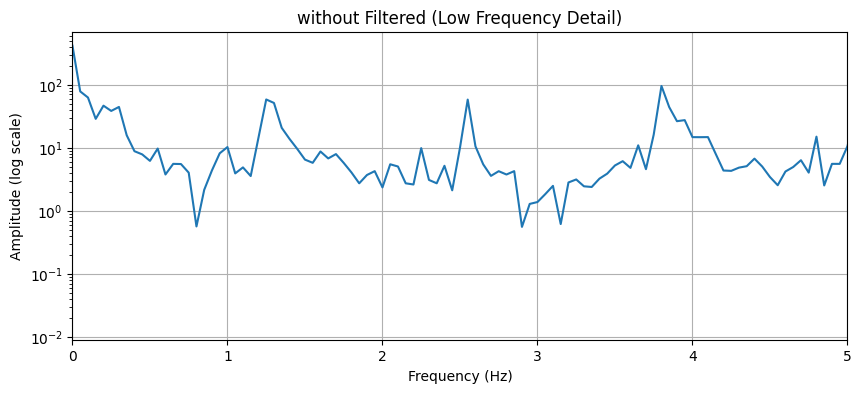

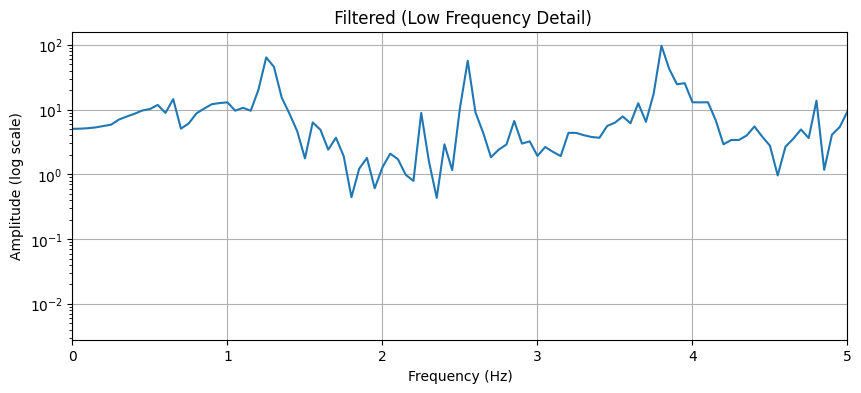

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(lead_iii[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_iii[:5000], fs, " Filtered")


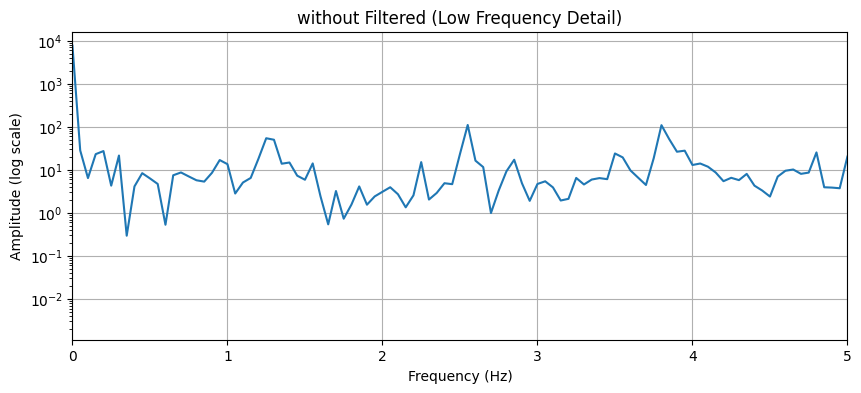

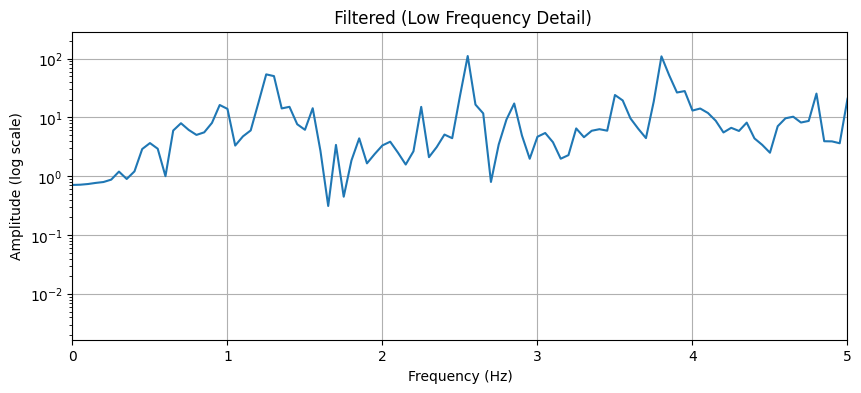

In [ ]:
def plot_frequency_spectrum(signal, fs, title=""):
    N = len(signal)
    yf = np.abs(fft(signal))
    xf = fftfreq(N, 1/fs)

    plt.figure(figsize=(10,4))
    plt.semilogy(xf[:N//2], yf[:N//2])  # Logarithmic y-axis
    plt.xlim(0, 5)  # Zoom in on 0-5 Hz range
    plt.title(title + " (Low Frequency Detail)")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Amplitude (log scale)")
    plt.grid()
    plt.show()

plot_frequency_spectrum(lead_v4[:5000], fs, "without Filtered")
plot_frequency_spectrum(filtered_v4[:5000], fs, " Filtered")


# ***Segmentation***

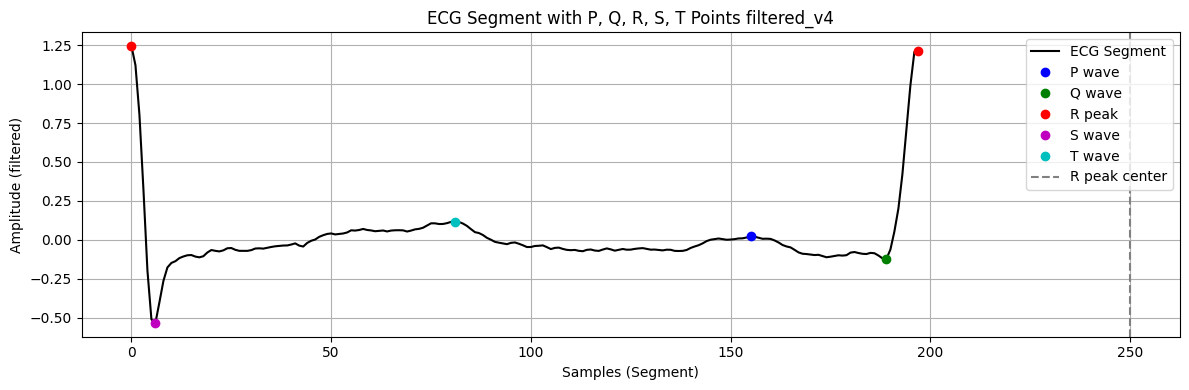

In [17]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
ListFilesIschemiques=os.listdir(f"{WORK_DIR}/ECG_Data/Ischemic")
ListFilesIschemiques=[x for x in ListFilesIschemiques if x[-4:]=='.dat' ]
i=0
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # 1. High-pass filter (e.g., 0.5 Hz)
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter (e.g., 45 Hz)

    # 3. Notch filter (e.g., 50 Hz or 60 Hz depending on country)
    signal = notch_filter(signal, 50.0, fs)  # Use 60.0 if you're in North America
    signal = lowpass_filter(signal, 100.0, fs)

    return signal

path=f"{WORK_DIR}/ECG_Data/Ischemic"
if i> len(ListFilesIschemiques) :
  z=len(ListFilesIschemiques)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesIschemiques[z][:-4]}')
fs = record.fs
channel_names = record.sig_name

# Get each lead separately
idx_iii = channel_names.index('MLIII')
idx_v4 = channel_names.index('V4')

lead_iii = record.p_signal[:, idx_iii]
lead_v4 = record.p_signal[:, idx_v4]

# Filter each lead
filtered_v4 = preprocess_ecg(lead_v4, fs)




def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa


r_peaks, mwa_signal = pan_tompkins(filtered_v4, fs)


# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(filtered_v4, r_peaks, fs)

# Choose one valid R-peak (e.g., first one with a valid segment)
r = r_peaks[2]
start = r
end = r_peaks[3]+1

# Check bounds
if start >= 0 and end <= len(filtered_v4):
    segment = filtered_v4[start:end]

    # Adjust PQRST indices relative to segment start
    p_in_segment = [p for p in p_waves if start <= p < end]
    q_in_segment = [q for q in q_waves if start <= q < end]
    s_in_segment = [s for s in s_waves if start <= s < end]
    t_in_segment = [t for t in t_waves if start <= t < end]
    r_in_segment =[t for t in r_peaks if start <= t < end] # center R-peak, already chosen

    # Convert to segment-relative indices
    p_rel = [p - start for p in p_in_segment]
    q_rel = [q - start for q in q_in_segment]
    r_rel = [r - start for r in r_in_segment]
    s_rel = [s - start for s in s_in_segment]
    t_rel = [t - start for t in t_in_segment]

    # Plot
    plt.figure(figsize=(12, 4))
    plt.plot(segment, label='ECG Segment', color='black')
    plt.plot(p_rel, segment[p_rel], 'bo', label='P wave')
    plt.plot(q_rel, segment[q_rel], 'go', label='Q wave')
    plt.plot(r_rel, segment[r_rel], 'ro', label='R peak')
    plt.plot(s_rel, segment[s_rel], 'mo', label='S wave')
    plt.plot(t_rel, segment[t_rel], 'co', label='T wave')

    plt.axvline(250, color='gray', linestyle='--', label='R peak center')
    plt.title("ECG Segment with P, Q, R, S, T Points filtered_v4")
    plt.xlabel("Samples (Segment)")
    plt.ylabel("Amplitude (filtered)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Segment out of bounds.")



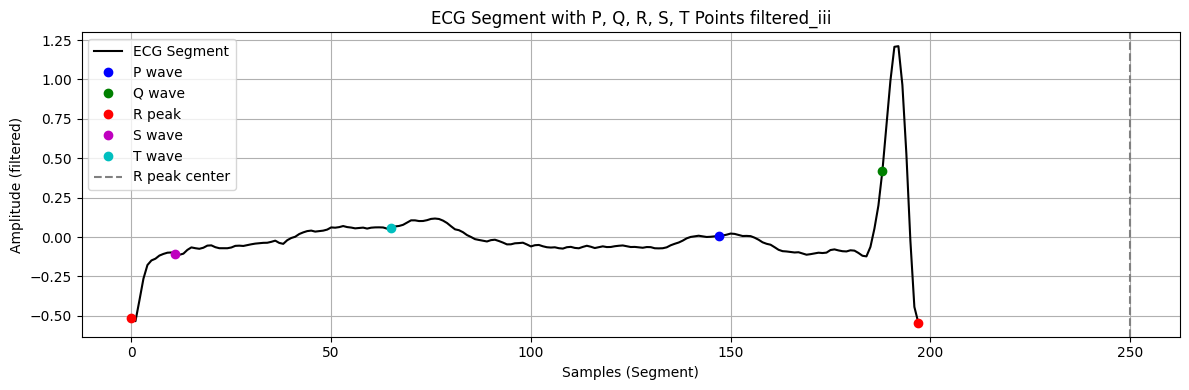

In [18]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
ListFilesIschemiques=os.listdir(f"{WORK_DIR}/ECG_Data/Ischemic")
ListFilesIschemiques=[x for x in ListFilesIschemiques if x[-4:]=='.dat' ]
i=0
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # 1. High-pass filter (e.g., 0.5 Hz)
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter (e.g., 45 Hz)

    # 3. Notch filter (e.g., 50 Hz or 60 Hz depending on country)
    signal = notch_filter(signal, 50.0, fs)  # Use 60.0 if you're in North America
    signal = lowpass_filter(signal, 100.0, fs)

    return signal

path=f"{WORK_DIR}/ECG_Data/Ischemic"
if i> len(ListFilesIschemiques) :
  z=len(ListFilesIschemiques)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesIschemiques[z][:-4]}')
fs = record.fs
channel_names = record.sig_name

# Get each lead separately
idx_iii = channel_names.index('MLIII')
idx_v4 = channel_names.index('V4')

lead_iii = record.p_signal[:, idx_iii]
lead_v4 = record.p_signal[:, idx_v4]

# Filter each lead
filtered_iii = preprocess_ecg(lead_iii, fs)




def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa


r_peaks, mwa_signal = pan_tompkins(filtered_iii, fs)


# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(filtered_iii, r_peaks, fs)

# Choose one valid R-peak (e.g., first one with a valid segment)
r = r_peaks[2]
start = r
end = r_peaks[3]+1

# Check bounds
if start >= 0 and end <= len(filtered_v4):
    segment = filtered_v4[start:end]

    # Adjust PQRST indices relative to segment start
    p_in_segment = [p for p in p_waves if start <= p < end]
    q_in_segment = [q for q in q_waves if start <= q < end]
    s_in_segment = [s for s in s_waves if start <= s < end]
    t_in_segment = [t for t in t_waves if start <= t < end]
    r_in_segment =[t for t in r_peaks if start <= t < end] # center R-peak, already chosen

    # Convert to segment-relative indices
    p_rel = [p - start for p in p_in_segment]
    q_rel = [q - start for q in q_in_segment]
    r_rel = [r - start for r in r_in_segment]
    s_rel = [s - start for s in s_in_segment]
    t_rel = [t - start for t in t_in_segment]

    # Plot
    plt.figure(figsize=(12, 4))
    plt.plot(segment, label='ECG Segment', color='black')
    plt.plot(p_rel, segment[p_rel], 'bo', label='P wave')
    plt.plot(q_rel, segment[q_rel], 'go', label='Q wave')
    plt.plot(r_rel, segment[r_rel], 'ro', label='R peak')
    plt.plot(s_rel, segment[s_rel], 'mo', label='S wave')
    plt.plot(t_rel, segment[t_rel], 'co', label='T wave')

    plt.axvline(250, color='gray', linestyle='--', label='R peak center')
    plt.title("ECG Segment with P, Q, R, S, T Points filtered_iii")
    plt.xlabel("Samples (Segment)")
    plt.ylabel("Amplitude (filtered)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Segment out of bounds.")



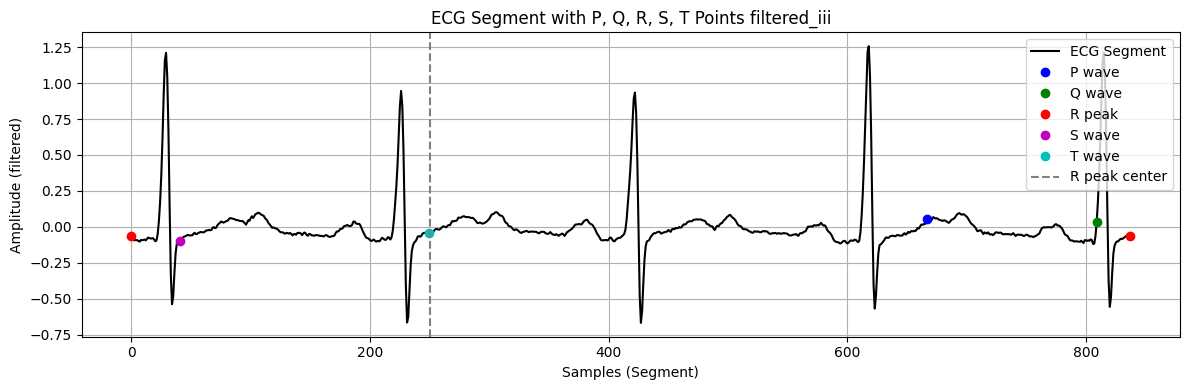

In [25]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch
ListFilesNormal=os.listdir(f"{WORK_DIR}/ECG_Data/Normal")
ListFilesNormal=[x for x in ListFilesNormal if x[-4:]=='.dat' ]
i=3
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # 1. High-pass filter (e.g., 0.5 Hz)
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter (e.g., 45 Hz)

    # 3. Notch filter (e.g., 50 Hz or 60 Hz depending on country)
    signal = notch_filter(signal, 50.0, fs)  # Use 60.0 if you're in North America
    signal = lowpass_filter(signal, 100.0, fs)

    return signal

path=f"{WORK_DIR}/ECG_Data/Normal"
if i> len(ListFilesNormal) :
  z=len(ListFilesNormal)-1
elif i<0 :
  z=0
else:
  z=i
# === Load ECG signal ===
record = wfdb.rdrecord(f'{path}/{ListFilesNormal[z][:-4]}')
fs = record.fs
channel_names = record.sig_name

# Get each lead separately
idx_iii = channel_names.index('iii')
idx_v4 = channel_names.index('v4')

lead_iii = record.p_signal[:, idx_iii]
lead_v4 = record.p_signal[:, idx_v4]

# Filter each lead
filtered_iii = preprocess_ecg(lead_iii, fs)




def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa


r_peaks, mwa_signal = pan_tompkins(filtered_iii, fs)


# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

# === Get P, Q, S, T ===
p_waves, q_waves, s_waves, t_waves = detect_pqrst(filtered_iii, r_peaks, fs)

# Choose one valid R-peak (e.g., first one with a valid segment)
r = r_peaks[4]
start = r
end = r_peaks[5]+1

# Check bounds
if start >= 0 and end <= len(filtered_v4):
    segment = filtered_v4[start:end]

    # Adjust PQRST indices relative to segment start
    p_in_segment = [p for p in p_waves if start <= p < end]
    q_in_segment = [q for q in q_waves if start <= q < end]
    s_in_segment = [s for s in s_waves if start <= s < end]
    t_in_segment = [t for t in t_waves if start <= t < end]
    r_in_segment =[t for t in r_peaks if start <= t < end] # center R-peak, already chosen

    # Convert to segment-relative indices
    p_rel = [p - start for p in p_in_segment]
    q_rel = [q - start for q in q_in_segment]
    r_rel = [r - start for r in r_in_segment]
    s_rel = [s - start for s in s_in_segment]
    t_rel = [t - start for t in t_in_segment]

    # Plot
    plt.figure(figsize=(12, 4))
    plt.plot(segment, label='ECG Segment', color='black')
    plt.plot(p_rel, segment[p_rel], 'bo', label='P wave')
    plt.plot(q_rel, segment[q_rel], 'go', label='Q wave')
    plt.plot(r_rel, segment[r_rel], 'ro', label='R peak')
    plt.plot(s_rel, segment[s_rel], 'mo', label='S wave')
    plt.plot(t_rel, segment[t_rel], 'co', label='T wave')

    plt.axvline(250, color='gray', linestyle='--', label='R peak center')
    plt.title("ECG Segment with P, Q, R, S, T Points filtered_iii")
    plt.xlabel("Samples (Segment)")
    plt.ylabel("Amplitude (filtered)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Segment out of bounds.")



In [ ]:
#//// FINNNN ////

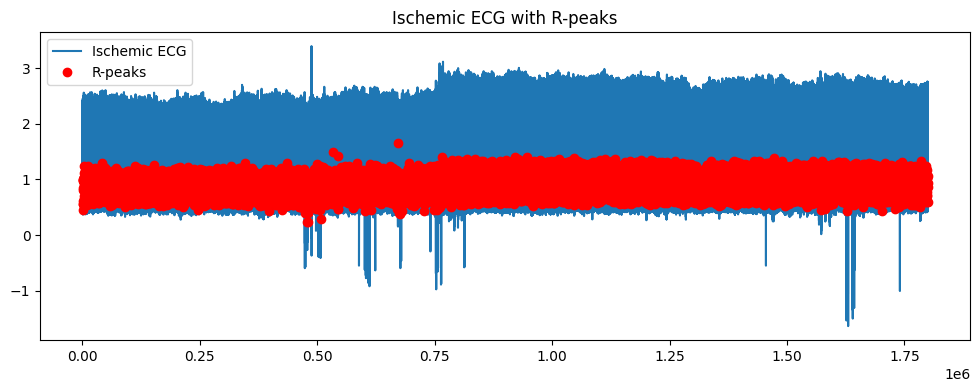

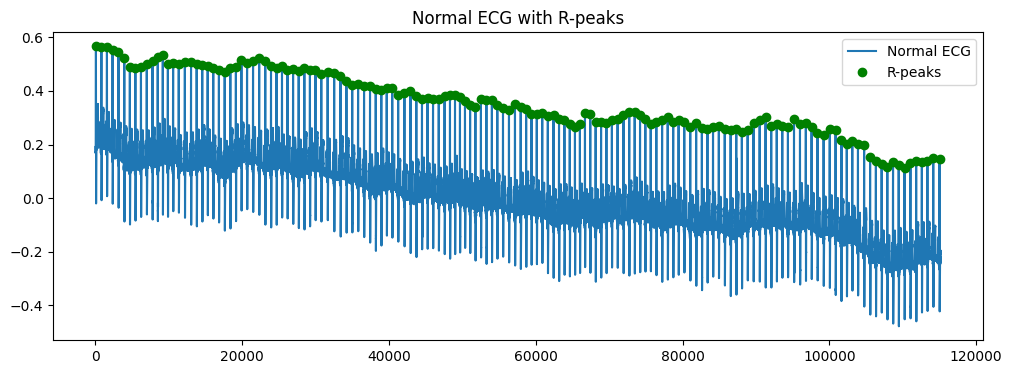

In [ ]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

def load_ecg(record_path, is_ischemic=True):
    record = wfdb.rdrecord(record_path)
    signal = record.p_signal[:, 0]  # Take channel 0
    fs = record.fs

    if is_ischemic:
        # Load annotations for ischemic signal
        ann = wfdb.rdann(record_path, 'atr')
        r_peaks = ann.sample
    else:
        # No annotations: detect R-peaks automatically
        r_peaks, _ = find_peaks(signal, distance=fs*0.6, height=np.mean(signal))

    return signal, fs, r_peaks

# === Example 1: Ischemic ECG ===
ischemic_path = f"{WORK_DIR}/ECG_Data/Ischemic/e0103"  # Without extension
signal1, fs1, r_peaks1 = load_ecg(ischemic_path, is_ischemic=True)

# === Example 2: Normal ECG ===
normal_path = f"{WORK_DIR}/ECG_Data/Normal/s0301lre"  # Without extension
signal2, fs2, r_peaks2 = load_ecg(normal_path, is_ischemic=False)

# === Plot for ischemic signal ===
plt.figure(figsize=(12, 4))
plt.plot(signal1, label='Ischemic ECG')
plt.plot(r_peaks1, signal1[r_peaks1], 'ro', label='R-peaks')
plt.title('Ischemic ECG with R-peaks')
plt.legend()
plt.show()

# === Plot for normal signal ===
plt.figure(figsize=(12, 4))
plt.plot(signal2, label='Normal ECG')
plt.plot(r_peaks2, signal2[r_peaks2], 'go', label='R-peaks')
plt.title('Normal ECG with R-peaks')
plt.legend()
plt.show()


In [ ]:
##########################3 Extraction des caracteristique

In [ ]:
import numpy as np
from scipy import integrate
from scipy.fft import fft
from math import log2

# 1. Amplitude du segment ST
def amplitude_st(V_ST, V_base):
    return V_ST - V_base

# 2. Durée du segment ST
def duree_st(t_Tdebut, t_J):
    return t_Tdebut - t_J

# 3. Ratio ST/T
def ratio_st_t(A_ST, A_T):
    return A_ST / A_T if A_T != 0 else None

# 4. Amplitude onde T
def amplitude_t(V_Tpic, V_base):
    return V_Tpic - V_base

# 5. Durée onde T
def duree_t(t_Tfin, t_Tdebut):
    return t_Tfin - t_Tdebut

# 6. Intervalle QT
def intervalle_qt(t_Tfin, t_Qdebut):
    return t_Tfin - t_Qdebut

# 7. Amplitude complexe QRS
def amplitude_qrs(V_R, V_Q, V_S):
    return max([V_R, V_Q, V_S]) - min([V_R, V_Q, V_S])


# 8. Durée complexe QRS
def duree_qrs(t_QRSfin, t_QRSdebut):
    return t_QRSfin - t_QRSdebut

# 9. Amplitude onde Q
def amplitude_q(V_Qmin, V_base):
    return V_Qmin - V_base

# 10. Pente du segment ST
def pente_st(V_Tdebut, V_J, t_Tdebut, t_J):
    return (V_Tdebut - V_J) / (t_Tdebut - t_J) if (t_Tdebut - t_J) != 0 else None

# 11. Aire de courbure ST (intégrale entre t_J et t_Tdebut)
def aire_st(signal, t, V_base):
    # Assumes `signal` is ECG values and `t` is corresponding times
    diff = signal - V_base
    return integrate.simpson(diff, t)

# 12. Intervalle R-R
def intervalle_rr(t_R2, t_R1):
    return t_R2 - t_R1

# 13. Asymétrie onde T
def asymetrie_t(t_Tpic, t_Tdebut, t_Tfin):
    denom = t_Tfin - t_Tpic
    return (t_Tpic - t_Tdebut) / denom if denom != 0 else None

# 14. Énergie du signal
def energie_ecg(signal):
    return np.sum(np.square(signal))

# 15. Entropie de Shannon
def entropie_shannon(signal):
    histogram, _ = np.histogram(signal, bins=256, density=True)
    p = histogram[histogram > 0]
    return -np.sum(p * np.log2(p))

# 16. Fréquence dominante
def frequence_dominante(signal, fs):
    # fs is the sampling frequency
    freqs = np.fft.fftfreq(len(signal), d=1/fs)
    magnitudes = np.abs(fft(signal))
    return freqs[np.argmax(magnitudes[:len(freqs)//2])]

# 17. Variance
def variance(signal):
    return np.var(signal)

# 18. Moyenne mobile
def moyenne_mobile(signal, w):
    return np.convolve(signal, np.ones(w)/w, mode='valid')


In [ ]:
from scipy.signal import butter, filtfilt, find_peaks
import numpy as np

def pan_tompkins(ecg_signal, fs):
    """
    Implements Pan-Tompkins QRS detection algorithm.
    Returns:
        r_peaks: Indices of detected R-peaks
        mwa: Moving window integrated signal
    """



    # === 2. Derivative
    diff = np.diff(ecg_signal, prepend=ecg_signal[0])

    # === 3. Squaring
    squared = diff ** 2

    # === 4. Moving window integration (~150ms)
    window_size = int(0.15 * fs)
    mwa = np.convolve(squared, np.ones(window_size)/window_size, mode='same')

    # === 5. Peak detection on MWI signal
    threshold = np.mean(mwa) * 1.5
    raw_peaks, _ = find_peaks(mwa, height=threshold, distance=int(0.6 * fs))

    # === 6. Refine R-peaks: search for local max around each peak in original signal
    search_radius = int(0.1 * fs)  # 100ms before and after
    r_peaks = []

    for peak in raw_peaks:
        start = max(0, peak - search_radius)
        end = min(len(ecg_signal), peak + search_radius)
        local_max_idx = np.argmax(ecg_signal[start:end])
        r_peaks.append(start + local_max_idx)

    return np.array(r_peaks), mwa




# === PQRST Detection Function ===
def detect_pqrst(signal, r_peaks, fs):
    p_waves = []
    q_waves = []
    s_waves = []
    t_waves = []

    for r in r_peaks:
        # Define windows (you can tune these values)
        p_win = int(0.2 * fs)
        q_win = int(0.05 * fs)
        s_win = int(0.05 * fs)
        t_win = int(0.4 * fs)

        # Q wave = min before R
        if r - q_win >= 0:
            q_segment = signal[r - q_win:r]
            q_idx = np.argmin(q_segment)
            q_waves.append(r - q_win + q_idx)

        # S wave = min after R
        if r + s_win < len(signal):
            s_segment = signal[r:r + s_win]
            s_idx = np.argmin(s_segment)
            s_waves.append(r + s_idx)

        # P wave = max before Q (or R if Q not found)
        p_start = max(0, r - p_win)
        p_segment = signal[p_start:r - q_win] if r - q_win > p_start else signal[p_start:r]
        if len(p_segment) > 0:
            p_idx = np.argmax(p_segment)
            p_waves.append(p_start + p_idx)

        # T wave = max after S
        t_start = r + s_win
        t_end = min(len(signal), r + t_win)
        t_segment = signal[t_start:t_end]
        if len(t_segment) > 0:
            t_idx = np.argmax(t_segment)
            t_waves.append(t_start + t_idx)

    return np.array(p_waves), np.array(q_waves), np.array(s_waves), np.array(t_waves)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import find_peaks
from scipy.fft import fft
from scipy import integrate
from math import log2


In [ ]:
import numpy as np
from scipy.signal import butter, filtfilt, iirnotch
import cupy as cp

# === High-pass filter ===
def highpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return filtfilt(b, a, signal)

# === Low-pass filter ===
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

# === Notch filter ===
def notch_filter(signal, notch_freq, fs, quality=30):
    nyq = 0.5 * fs
    b, a = iirnotch(notch_freq / nyq, quality)
    return filtfilt(b, a, signal)

# === Apply all filters ===
def preprocess_ecg(signal, fs):
    # Convert CuPy input to NumPy for SciPy filtering
    if isinstance(signal, cp.ndarray):
        signal = signal.get()

    # 1. High-pass filter
    signal = highpass_filter(signal, 0.5, fs)

    # 2. Low-pass filter
    signal = lowpass_filter(signal, 45.0, fs)

    # 3. Notch filter (50 Hz for EU/UK, 60 Hz for US)
    signal = notch_filter(signal, 50.0, fs)

    return signal  # Still NumPy — convert to CuPy later if needed


In [ ]:
def process_ecg_file(filepath, label):
    record = wfdb.rdrecord(filepath)
    signal = record.p_signal[:, 0]
    fs = record.fs
    channel_names = [name.lower() for name in record.sig_name]
    idx_v4 = channel_names.index('v4')
    lead_v4 = record.p_signal[:, idx_v4]

    filtered = preprocess_ecg(lead_v4, fs)
    normed = (filtered - np.mean(filtered)) / np.std(filtered)

    r_peaks, _ = pan_tompkins(normed, fs)
    p, q, s, t = detect_pqrst(normed, r_peaks, fs)

    feature_list = []
    for i in range(min(len(r_peaks), len(p), len(q), len(s), len(t))):
        features = []
        try:
            V_base = normed[q[i]]
            V_ST = normed[t[i]]
            V_Tpic = normed[t[i]]
            t_Tdebut = t[i]
            t_Tfin = t[i] + int(0.1 * fs)
            t_Qdebut = q[i]
            t_J = s[i]
            t_QRSdebut = q[i]
            t_QRSfin = s[i]
            V_R = normed[r_peaks[i]]
            V_Q = normed[q[i]]
            V_S = normed[s[i]]
            V_Qmin = V_Q
            V_Tdebut = normed[t[i]]
            V_J = normed[s[i]]

            signal_segment = normed[t_J:t_Tdebut]
            time_segment = np.linspace(t_J, t_Tdebut, len(signal_segment))

            features.extend([
                amplitude_st(V_ST, V_base),
                duree_st(t_Tdebut, t_J),
                ratio_st_t(amplitude_st(V_ST, V_base), amplitude_t(V_Tpic, V_base)),
                amplitude_t(V_Tpic, V_base),
                duree_t(t_Tfin, t_Tdebut),
                intervalle_qt(t_Tfin, t_Qdebut),
                amplitude_qrs(V_R, V_Q, V_S),
                duree_qrs(t_QRSfin, t_QRSdebut),
                amplitude_q(V_Qmin, V_base),
                pente_st(V_Tdebut, V_J, t_Tdebut, t_J),
                aire_st(signal_segment, time_segment, V_base),
                intervalle_rr(r_peaks[i + 1], r_peaks[i]) if i + 1 < len(r_peaks) else 0,
                asymetrie_t(t[i], t_Tdebut, t_Tfin),
                energie_ecg(normed),
                entropie_shannon(normed),
                frequence_dominante(normed, fs),
                variance(normed),
                np.mean(moyenne_mobile(normed, 5))
            ])
            feature_list.append((features, label))
        except:
            continue
    return feature_list


In [ ]:
def process_ecg_file(filepath, label):
    record = wfdb.rdrecord(filepath)
    fs = record.fs

    channel_names = [name.lower() for name in record.sig_name]
    idx_v4 = channel_names.index('v4')
    lead_v4 = record.p_signal[:, idx_v4]

    # Preprocess
    filtered = preprocess_ecg(lead_v4, fs)
    normed = (filtered - np.mean(filtered)) / np.std(filtered)

    # Detect R-peaks
    r_peaks, _ = pan_tompkins(normed, fs)

    # Features per R-R segment
    feature_list = []
    for i in range(len(r_peaks) - 1):
        start = r_peaks[i]
        end = r_peaks[i + 1]
        segment = normed[start:end]

        if len(segment) < 10:
            continue  # skip too-short segments

        features = extract_stat_entropy_features(segment)
        feature_list.append((features, label))

    return feature_list


In [ ]:
from concurrent.futures import ProcessPoolExecutor
import multiprocessing
path_ischemic = f"{WORK_DIR}/ECG_Data/Ischemic"
path_normal = f"{WORK_DIR}/ECG_Data/Normal"

ischemic_files = [f for f in os.listdir(path_ischemic) if f.endswith('.dat')]
normal_files = [f for f in os.listdir(path_normal) if f.endswith('.dat')]
# === Prepare all file paths with labels ===
all_file_paths = [(os.path.join(path_ischemic, f[:-4]), 1) for f in ischemic_files] + \
                 [(os.path.join(path_normal, f[:-4]), 0) for f in normal_files]

# === Parallel processing ===
all_features = []
all_labels = []

def process_wrapper(args):
    return process_ecg_file(*args)

with ProcessPoolExecutor(max_workers=multiprocessing.cpu_count()) as executor:
    results = executor.map(process_wrapper, all_file_paths)

# Flatten results
for result in results:
    for features, label in result:
        all_features.append(features)
        all_labels.append(label)

all_features = np.array(all_features)
all_labels = np.array(all_labels)


KeyboardInterrupt: 

In [ ]:
import os
import wfdb
import pandas as pd
import numpy as np

# Define paths
path_ischemic = f"{WORK_DIR}/ECG_Data/Ischemic"
path_normal = f"{WORK_DIR}/ECG_Data/Normal"
csv_path = f"{WORK_DIR}/features.csv"

# Get .dat files
ischemic_files = [(os.path.join(path_ischemic, f[:-4]), f, 1) for f in os.listdir(path_ischemic) if f.endswith('.dat')]
normal_files = [(os.path.join(path_normal, f[:-4]), f, 0) for f in os.listdir(path_normal) if f.endswith('.dat')]

# Combine and shuffle
all_files = ischemic_files + normal_files

# Check already processed filenames
if os.path.exists(csv_path):
    processed_df = pd.read_csv(csv_path)
    processed_files = set(processed_df['filename'].unique())
else:
    processed_files = set()

# Process only one unprocessed file
file_to_process = None
for full_path, fname, label in all_files:
    if fname not in processed_files:
        file_to_process = (full_path, fname, label)
        break

if file_to_process is None:
    print("✅ All files processed.")
else:
    print(f"🚀 Processing file: {file_to_process[1]}")
    full_path, fname, label = file_to_process

    try:
        results = process_ecg_file(full_path, label)  # This returns list of (features, label)
        if results:
            # Create DataFrame for this file
            feature_names = [
                'amplitude_st', 'duree_st', 'ratio_st_t', 'amplitude_t', 'duree_t',
                'intervalle_qt', 'amplitude_qrs', 'duree_qrs', 'amplitude_q', 'pente_st',
                'aire_st', 'intervalle_rr', 'asymetrie_t', 'energie_ecg', 'entropie_shannon',
                'frequence_dominante', 'variance', 'moyenne_mobile'
            ]
            data = [feat + [label, fname] for feat, label in results]
            df = pd.DataFrame(data, columns=feature_names + ['label', 'filename'])

            # Append to CSV
            if os.path.exists(csv_path):
                df.to_csv(csv_path, mode='a', header=False, index=False)
            else:
                df.to_csv(csv_path, index=False)

            print(f"✅ File processed and saved: {fname}")
        else:
            print(f"⚠️ No data extracted from: {fname}")
    except Exception as e:
        print(f"❌ Error processing {fname}: {e}")


🚀 Processing file: e0125.dat


In [ ]:
!pip install cupy-cuda12x -q  # or -cuda12x depending on your GPU runtime


In [ ]:
# 1. Amplitude du segment ST
def amplitude_st(V_ST, V_base):
    return V_ST - V_base

# 2. Durée du segment ST
def duree_st(t_Tdebut, t_J):
    return t_Tdebut - t_J

# 3. Ratio ST/T
def ratio_st_t(A_ST, A_T):
    return A_ST / A_T if A_T != 0 else 0

# 4. Amplitude onde T
def amplitude_t(V_Tpic, V_base):
    return V_Tpic - V_base

# 5. Durée onde T
def duree_t(t_Tfin, t_Tdebut):
    return t_Tfin - t_Tdebut

# 6. Intervalle QT
def intervalle_qt(t_Tfin, t_Qdebut):
    return t_Tfin - t_Qdebut

# 7. Amplitude complexe QRS
def amplitude_qrs(V_R, V_Q, V_S):
    return max([V_R, V_Q, V_S]) - min([V_R, V_Q, V_S])

# 8. Durée complexe QRS
def duree_qrs(t_QRSfin, t_QRSdebut):
    return t_QRSfin - t_QRSdebut

# 9. Amplitude onde Q
def amplitude_q(V_Qmin, V_base):
    return V_Qmin - V_base

# 10. Pente du segment ST
def pente_st(V_Tdebut, V_J, t_Tdebut, t_J):
    return (V_Tdebut - V_J) / (t_Tdebut - t_J) if (t_Tdebut - t_J) != 0 else 0

# 11. Aire de courbure ST (intégrale entre t_J et t_Tdebut)
def aire_st(signal, t, V_base):
    signal = cp.asarray(signal)
    t = cp.asarray(t)
    diff = signal - V_base
    diff_np = cp.asnumpy(diff)
    t_np = cp.asnumpy(t)
    return integrate.simpson(diff_np, t_np)

# 12. Intervalle R-R
def intervalle_rr(t_R2, t_R1):
    return t_R2 - t_R1

# 13. Asymétrie onde T
def asymetrie_t(t_Tpic, t_Tdebut, t_Tfin):
    denom = t_Tfin - t_Tpic
    return (t_Tpic - t_Tdebut) / denom if denom != 0 else 0

# 14. Énergie du signal
def energie_ecg(signal):
    signal = cp.asarray(signal)
    return cp.sum(cp.square(signal)).item()

# 15. Entropie de Shannon
def entropie_shannon(signal):
    signal = cp.asarray(signal)
    hist, _ = cp.histogram(signal, bins=256, density=True)
    p = hist[hist > 0]
    return float(-cp.sum(p * cp.log2(p)))

# 16. Fréquence dominante
def frequence_dominante(signal, fs):
    signal = cp.asarray(signal)
    signal_np = cp.asnumpy(signal)
    freqs = np.fft.fftfreq(len(signal_np), d=1/fs)
    magnitudes = np.abs(fft(signal_np))
    return freqs[np.argmax(magnitudes[:len(freqs)//2])]

# 17. Variance
def variance(signal):
    signal = cp.asarray(signal)
    return cp.var(signal).item()

# 18. Moyenne mobile
def moyenne_mobile(signal, w):
    signal = cp.asarray(signal)
    window = cp.ones(w) / w
    return cp.convolve(signal, window, mode='valid')


In [ ]:
import cupy as cp
from scipy import integrate
from scipy.fft import fft  # We’ll still use FFT from SciPy on CPU for now unless you convert signal to NumPy


In [ ]:
import cupy as cp

def process_ecg_file(filepath, label):
    record = wfdb.rdrecord(filepath)
    channel_names = [name.lower() for name in record.sig_name]
    idx_v4 = channel_names.index('v4')
    lead_v4 = record.p_signal[:, idx_v4]
    fs = record.fs

    # Convert to CuPy
    lead_v4 = cp.asarray(lead_v4)

    # Preprocess (assuming this supports CuPy — if not, wrap it with .get())
    filtered = preprocess_ecg(lead_v4, fs)

    # Normalize
    normed = (filtered - cp.mean(filtered)) / cp.std(filtered)

    # Convert back to NumPy for CPU-based ops (like pan_tompkins, detect_pqrst, etc.)
    normed_np = normed.get() if isinstance(normed, cp.ndarray) else normed

    r_peaks, _ = pan_tompkins(normed_np, fs)
    p, q, s, t = detect_pqrst(normed_np, r_peaks, fs)

    result = []

    for i in range(min(len(r_peaks), len(p), len(q), len(s), len(t))):
        try:
            # Extract relevant signal points
            V_base = normed_np[q[i]]
            V_ST = normed_np[t[i]]
            V_Tpic = normed_np[t[i]]
            t_Tdebut = t[i]
            t_Tfin = t[i] + int(0.1 * fs)
            t_Qdebut = q[i]
            t_J = s[i]
            t_QRSdebut = q[i]
            t_QRSfin = s[i]
            V_R = normed_np[r_peaks[i]]
            V_Q = normed_np[q[i]]
            V_S = normed_np[s[i]]
            V_Qmin = V_Q
            V_Tdebut = normed_np[t[i]]
            V_J = normed_np[s[i]]

            signal_segment = normed_np[t_J:t_Tdebut]
            time_segment = np.linspace(t_J, t_Tdebut, len(signal_segment))

            # Convert segments to CuPy for CuPy-based functions
            signal_segment_cp = cp.asarray(signal_segment)
            time_segment_cp = cp.asarray(time_segment)
            normed_cp = cp.asarray(normed_np)

            # Feature calculation
            features = [
                amplitude_st(V_ST, V_base),
                duree_st(t_Tdebut, t_J),
                ratio_st_t(amplitude_st(V_ST, V_base), amplitude_t(V_Tpic, V_base)),
                amplitude_t(V_Tpic, V_base),
                duree_t(t_Tfin, t_Tdebut),
                intervalle_qt(t_Tfin, t_Qdebut),
                amplitude_qrs(V_R, V_Q, V_S),
                duree_qrs(t_QRSfin, t_QRSdebut),
                amplitude_q(V_Qmin, V_base),
                pente_st(V_Tdebut, V_J, t_Tdebut, t_J),
                aire_st(signal_segment_cp, time_segment_cp, V_base),  # CuPy-based
                intervalle_rr(r_peaks[i + 1], r_peaks[i]) if i + 1 < len(r_peaks) else 0,
                asymetrie_t(t[i], t_Tdebut, t_Tfin),
                energie_ecg(normed_cp),
                entropie_shannon(normed_cp),
                frequence_dominante(normed_np, fs),  # still CPU
                variance(normed_cp),
                cp.mean(moyenne_mobile(normed_cp, 5)).item()  # Ensure scalar
            ]

            result.append((features, label))

        except Exception as e:
            print(f"⚠️ Skipping beat {i} due to error: {e}")
            continue

    return result


In [ ]:
import os
import wfdb
import pandas as pd
import numpy as np
import cupy as cp

# === PATH SETUP ===
path_ischemic = f"{WORK_DIR}/ECG_Data/Ischemic"
path_normal = f"{WORK_DIR}/ECG_Data/Normal"
csv_path = f"{WORK_DIR}/features.csv"

# === LOAD FILES ===
ischemic_files = [(os.path.join(path_ischemic, f[:-4]), f, 1) for f in os.listdir(path_ischemic) if f.endswith('.dat')]
normal_files = [(os.path.join(path_normal, f[:-4]), f, 0) for f in os.listdir(path_normal) if f.endswith('.dat')]
all_files = ischemic_files + normal_files

# === CHECK FOR PROCESSED FILES ===
if os.path.exists(csv_path):
    processed_df = pd.read_csv(csv_path)
    processed_files = set(processed_df['filename'].unique())
else:
    processed_files = set()

# === PICK NEXT UNPROCESSED FILE ===
file_to_process = None
for full_path, fname, label in all_files:
    if fname not in processed_files:
        file_to_process = (full_path, fname, label)
        break

if file_to_process is None:
    print("✅ All files processed.")
else:
    print(f"🚀 Processing file: {file_to_process[1]}")
    full_path, fname, label = file_to_process


    results = process_ecg_file(full_path, label)

    if results:
            # === DEFINE FEATURE NAMES ===
            feature_names = [
                'amplitude_st', 'duree_st', 'ratio_st_t', 'amplitude_t', 'duree_t',
                'intervalle_qt', 'amplitude_qrs', 'duree_qrs', 'amplitude_q', 'pente_st',
                'aire_st', 'intervalle_rr', 'asymetrie_t', 'energie_ecg', 'entropie_shannon',
                'frequence_dominante', 'variance', 'moyenne_mobile'
            ]
            data = [feat + [label, fname] for feat, label in results]
            df = pd.DataFrame(data, columns=feature_names + ['label', 'filename'])

            # === SAVE TO CSV ===
            if os.path.exists(csv_path):
                df.to_csv(csv_path, mode='a', header=False, index=False)
            else:
                df.to_csv(csv_path, index=False)

            print(f"✅ File processed and saved: {fname}")
    else:
            print(f"⚠️ No features extracted from: {fname}")



🚀 Processing file: e0118.dat
✅ File processed and saved: e0118.dat


In [ ]:
import scipy
print(scipy.__version__)


1.15.3


In [ ]:
!pip install --upgrade scipy


In [ ]:
import pandas as pd

# Define feature names in the correct order
feature_names = [
    'amplitude_st',
    'duree_st',
    'ratio_st_t',
    'amplitude_t',
    'duree_t',
    'intervalle_qt',
    'amplitude_qrs',
    'duree_qrs',
    'amplitude_q',
    'pente_st',
    'aire_st',
    'intervalle_rr',
    'asymetrie_t',
    'energie_ecg',
    'entropie_shannon',
    'frequence_dominante',
    'variance',
    'moyenne_mobile'
]

# Create DataFrame
df = pd.DataFrame(all_features, columns=feature_names)
df['label'] = all_labels  # Add the label column

# Optional: show the first few rows
print(df.head())


ValueError: Shape of passed values is (0, 1), indices imply (0, 18)

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50)
beats_pca = pca.fit_transform(all_beats)
from sklearn.utils import resample

# Convertir en dataframe pour faciliter
import pandas as pd
df = pd.DataFrame(beats_pca)
df['label'] = all_labels

# Séparer
df_majority = df[df.label == 1]
df_minority = df[df.label == 0]

# Équilibrer
df_majority_downsampled = resample(df_majority,
                                   replace=False,
                                   n_samples=len(df_minority),
                                   random_state=42)

df_balanced = pd.concat([df_majority_downsampled, df_minority])
df_balanced = df_balanced.sample(frac=1)  # shuffle

X = df_balanced.drop('label', axis=1).values
y = df_balanced['label'].values


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

model = Sequential([
    Flatten(input_shape=(beats_pca.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')  # Binaire : 0 = normal, 1 = ischemic
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X , y, epochs=3, batch_size=32, validation_split=0.2)


Epoch 1/3


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


528/528 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9419 - loss: 0.1747 - val_accuracy: 0.9957 - val_loss: 0.0165
Epoch 2/3
528/528 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9979 - loss: 0.0089 - val_accuracy: 0.9979 - val_loss: 0.0096
Epoch 3/3
528/528 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9992 - loss: 0.0038 - val_accuracy: 0.9986 - val_loss: 0.0093


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = model.predict(beats_pca)
y_pred = (y_pred > 0.5).astype(int)

print(confusion_matrix(all_labels, y_pred))
print(classification_report(all_labels, y_pred))


8368/8368 ━━━━━━━━━━━━━━━━━━━━ 12s 1ms/step
[[ 10548      7]
 [   456 256756]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     10555
           1       1.00      1.00      1.00    257212

    accuracy                           1.00    267767
   macro avg       0.98      1.00      0.99    267767
weighted avg       1.00      1.00      1.00    267767



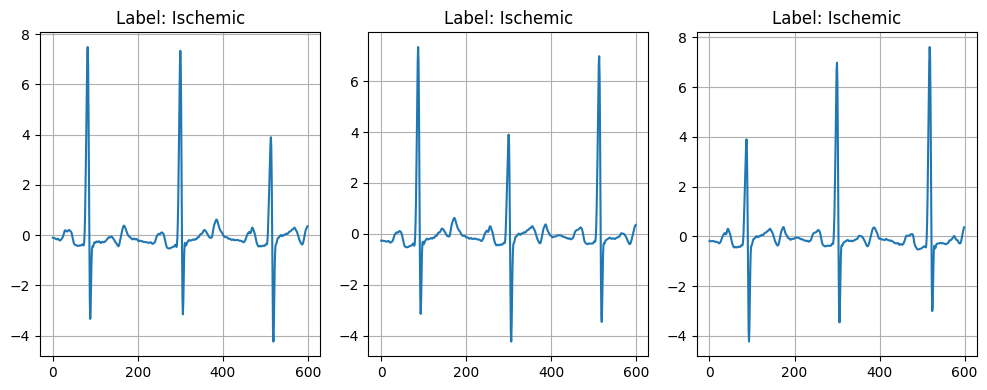

In [ ]:
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.plot(all_beats[i+3])
    plt.title(f"Label: {'Ischemic' if all_labels[i+3] else 'Normal'}")
    plt.grid()
plt.tight_layout()
plt.show()
